### 1. Initial data loading

In [5]:

from medmnist import INFO

info = INFO["bloodmnist"]

print("Dataset:", info["python_class"])
print("Number of classes:", len(info["label"]))

for number, name in info["label"].items():
    print(number, "-", name)


Dataset: BloodMNIST
Number of classes: 8
0 - basophil
1 - eosinophil
2 - erythroblast
3 - immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
4 - lymphocyte
5 - monocyte
6 - neutrophil
7 - platelet


In [6]:
import medmnist
from pathlib import Path

# Find the project folder
project_dir = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "requirements.txt").exists()),
    None
)

if project_dir is None:
    raise FileNotFoundError("Project folder not found")

# Create the data folder
data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

# Get the BloodMNIST dataset class
DataClass = getattr(medmnist, info["python_class"])

# Download and load the 224 x 224 datasets
train_dataset = DataClass(
    split="train", root=str(data_dir), download=True, size=224
)

val_dataset = DataClass(
    split="val", root=str(data_dir), download=True, size=224
)

test_dataset = DataClass(
    split="test", root=str(data_dir), download=True, size=224
)

# Check the number of images
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Image shape:", train_dataset.imgs.shape)
print("Data folder:", data_dir)


Train: 11959
Validation: 1712
Test: 3421
Image shape: (11959, 224, 224, 3)
Data folder: c:\Users\Asus\Desktop\Knowledge-Distillation\data


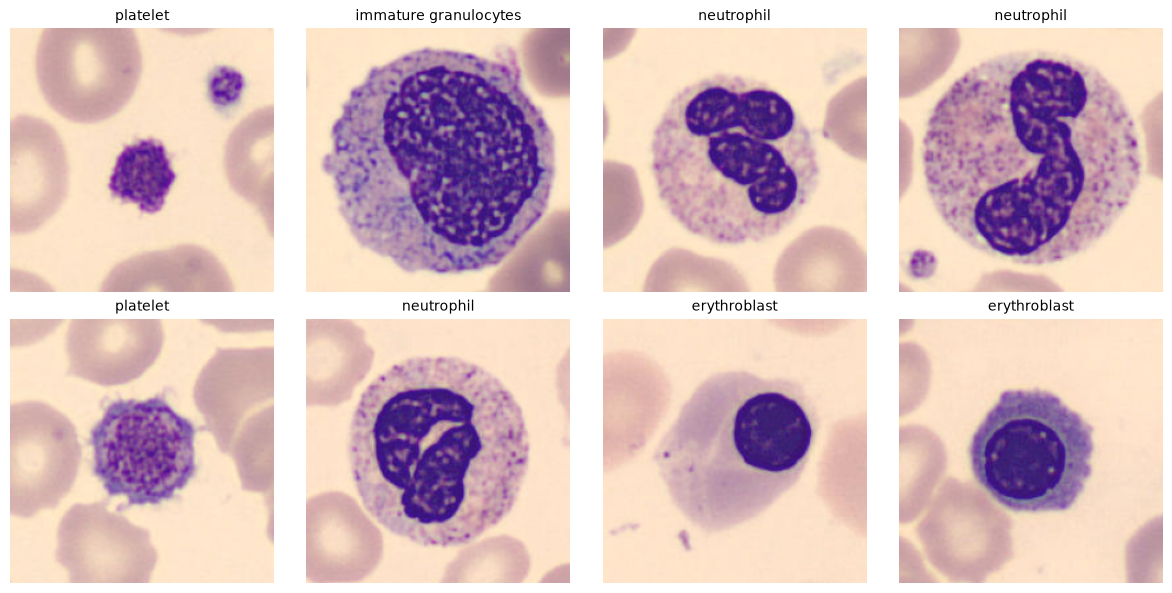

In [7]:

import matplotlib.pyplot as plt

# Create a figure with 2 rows and 4 columns
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# Display 8 images from the training dataset
for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # Get the class name
    class_name = info["label"][str(label.item())]

    # Shorten the long class name for display
    if class_name.startswith("immature granulocytes"):
        class_name = "immature granulocytes"

    # Display the image
    ax.imshow(image)

    # Add the class name above the image
    ax.set_title(class_name, fontsize=10)

    # Hide the axes
    ax.axis("off")

# Adjust spacing and display the figure
plt.tight_layout()
plt.show()


In [8]:

labels = train_dataset.labels

print("Shape:", labels.shape)
print("First 10 labels:", labels[:10])


Shape: (11959, 1)
First 10 labels: [[7]
 [3]
 [6]
 [6]
 [7]
 [6]
 [2]
 [2]
 [7]
 [2]]


In [9]:

import numpy as np

labels = train_dataset.labels
classes, counts = np.unique(labels, return_counts=True)

total = counts.sum()

for class_id, count in zip(classes, counts):
    class_name = info["label"][str(class_id)]
    percentage = (count / total) * 100

    print(f"{class_id} - {class_name}: {count} images ({percentage:.2f}%)")

print("Total:", total)



0 - basophil: 852 images (7.12%)
1 - eosinophil: 2181 images (18.24%)
2 - erythroblast: 1085 images (9.07%)
3 - immature granulocytes(myelocytes, metamyelocytes and promyelocytes): 2026 images (16.94%)
4 - lymphocyte: 849 images (7.10%)
5 - monocyte: 993 images (8.30%)
6 - neutrophil: 2330 images (19.48%)
7 - platelet: 1643 images (13.74%)
Total: 11959
